# 10-K Red Flag Detector — how it works and what it found

This notebook walks through a forensic accounting screener built on SEC filing data:
where the data comes from, the judgement calls that shape it, two bugs the real data
exposed, and whether the signals actually predicted anything.

**The question:** can you detect accounting manipulation from the numbers companies
file themselves?

**The short answer:** partly, and not in the way the textbook model claims. Sloan's
accrual signal separated future winners from losers by 8.5 percentage points
(p = 0.001). The Beneish M-Score did not — because it is partly measuring growth, not
manipulation. Working out *why* is most of what follows.

**Scope:** 309 S&P 500 companies outside Financials and Real Estate, 4,111
company-years, fiscal 2007–2026, all from SEC EDGAR.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"

fundamentals = pd.read_csv(PROC / "fundamentals.csv")
scored       = pd.read_csv(PROC / "scored.csv")
backtest     = pd.read_csv(PROC / "backtest.csv", parse_dates=["period_end", "entry", "exit"])
universe     = pd.read_csv(ROOT / "data" / "universe.csv")

print(f"companies      {fundamentals['ticker'].nunique():>8,}")
print(f"company-years  {len(fundamentals):>8,}")
print(f"fiscal years   {fundamentals['fiscal_year'].min()}-{fundamentals['fiscal_year'].max()}")
print(f"scoreable      {scored['m_score'].notna().sum():>8,}")

companies           309
company-years     4,111
fiscal years   2007-2026
scoreable         3,442


In [2]:
# Chart styling: recessive grid, thin marks, no chartjunk. Colours come from a
# validated palette -- blue/orange for two categories, blue/red diverging about zero.
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#d03b3b"
INK, MUTED, GRID  = "#0b0b0b", "#52514e", "#e3e2de"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

---
## Part 1 — The data problem nobody warns you about

The SEC publishes every number companies tag in their filings, free, through the
`companyfacts` API. The catch is that **there is no single tag for "revenue."**

A software company reports `RevenueFromContractWithCustomerExcludingAssessedTax`.
An industrial reports `Revenues`. A pre-2018 filing uses `SalesRevenueNet`. All three
mean the same thing to an analyst and nothing to a parser.

The pipeline keeps a dictionary of candidate tags per concept and records which one
supplied each number. That record is what the next cell counts.

In [3]:
tag_cols = [c for c in fundamentals.columns if c.startswith("tag_")]
diversity = (
    pd.DataFrame({
        "concept": [c.replace("tag_", "") for c in tag_cols],
        "distinct_tags": [fundamentals[c].nunique() for c in tag_cols],
        "companies_covered": [fundamentals.loc[fundamentals[c].notna(), "ticker"].nunique()
                              for c in tag_cols],
    })
    .sort_values("distinct_tags", ascending=False)
    .reset_index(drop=True)
)
print("How many different XBRL tags were needed per concept:\n")
print(diversity.head(10).to_string(index=False))

How many different XBRL tags were needed per concept:

          concept  distinct_tags  companies_covered
          revenue              5                309
             cogs              4                309
     depreciation              4                307
      receivables              4                309
       securities              4                179
   long_term_debt              3                286
income_continuing              3                305
       net_income              2                309
              sga              2                287
        inventory              2                257


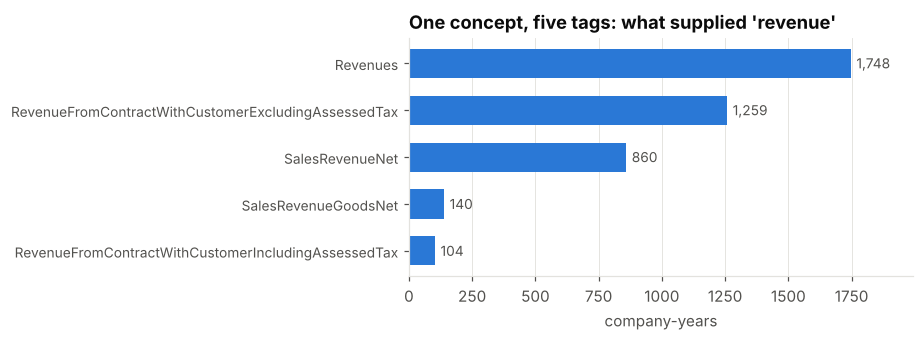


5 different tags, and a parser that stops at the first one covers only 43% of the data.


In [4]:
counts = fundamentals["tag_revenue"].value_counts()
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.barh(range(len(counts)), counts.values, color=BLUE, height=0.62)
ax.set_yticks(range(len(counts)))
ax.set_yticklabels([t[:52] for t in counts.index], fontsize=9)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("company-years")
ax.set_title("One concept, five tags: what supplied 'revenue'")
for i, v in enumerate(counts.values):
    ax.text(v + max(counts.values) * 0.012, i, f"{v:,}", va="center", fontsize=9, color=MUTED)
ax.set_xlim(0, max(counts.values) * 1.14)
plt.tight_layout(); plt.show()

print(f"\n{len(counts)} different tags, and a parser that stops at the first one "
      f"covers only {counts.iloc[0] / counts.sum():.0%} of the data.")

### The bug this caused

The first version of the parser walked the candidate tags and returned **the first tag
that held any data at all**. That seems reasonable until a company changes its tagging
mid-decade.

Caterpillar reported net income under `NetIncomeLoss` through 2010 and `ProfitLoss`
afterwards. The parser found `NetIncomeLoss`, got four years, and stopped — never
checking the tag that covered the other fifteen. Cost of goods had the opposite
coverage. The two windows didn't overlap, so **not one Caterpillar year was usable**.

The fix was to merge tags *year by year* rather than picking one tag for all years.
Coverage went from 46 company-years to 111 across the same eight test companies.

In [5]:
# Companies whose series is stitched from more than one tag -- the case that used to
# silently truncate them.
switchers = (
    fundamentals.groupby("ticker")[["tag_revenue", "tag_net_income", "tag_receivables"]]
    .nunique()
    .pipe(lambda d: d[(d > 1).any(axis=1)])
)
print(f"{len(switchers)} of {fundamentals['ticker'].nunique()} companies changed at least "
      f"one tag mid-history.\n")

example = fundamentals[fundamentals["ticker"] == switchers.index[0]]
print(f"Example — {example['company'].iloc[0]}:")
print(example.groupby("tag_revenue")["fiscal_year"].agg(["min", "max", "count"]).to_string())

229 of 309 companies changed at least one tag mid-history.

Example — AGILENT TECHNOLOGIES, INC.:


                                                      min   max  count
tag_revenue                                                           
RevenueFromContractWithCustomerExcludingAssessedTax  2018  2025      8
Revenues                                             2009  2017      9
SalesRevenueNet                                      2008  2008      1


### Three judgement calls baked into the data

**1. Which fiscal year a number belongs to.** A fact's `fy` field describes the *filing*
that carried it, so a 10-K filed in 2024 stamps its 2022 comparatives with `fy=2024`.
Fiscal years are derived from the period's own end date instead: the calendar year it
ends in, or the previous year when it ends before June. That puts Walmart's year ending
January 2026 alongside Apple's ending September 2025 — both cover mostly calendar 2025.

**2. Annual only.** A duration fact is kept only if it spans 340–400 days and arrived on
a 10-K, which excludes quarters and stub periods.

**3. As first reported, not as restated.** When a company restates a prior year, EDGAR
keeps both versions. This pipeline takes **what investors saw at the time**. Using the
corrected figures would leak the answer into the features — you'd be using the fix to
predict that the original was broken. That is data leakage, and it is the single most
common way a model like this fools its author.

In [6]:
wmt = fundamentals.loc[fundamentals["ticker"] == "WMT", ["fiscal_year", "period_end", "revenue"]].tail(3)
aapl = fundamentals.loc[fundamentals["ticker"] == "AAPL", ["fiscal_year", "period_end", "revenue"]].tail(3)
print("Fiscal-year alignment — different year ends, comparable periods:\n")
print("Walmart:"); print(wmt.to_string(index=False))
print("\nApple:");  print(aapl.to_string(index=False))

Fiscal-year alignment — different year ends, comparable periods:

Walmart:
 fiscal_year period_end      revenue
        2023 2024-01-31 6.481250e+11
        2024 2025-01-31 6.809850e+11
        2025 2026-01-31 7.131630e+11

Apple:
 fiscal_year period_end      revenue
        2024 2024-09-28 3.910350e+11
        2025 2025-09-27 4.161610e+11
        2026 2026-09-26 4.788340e+11


---
## Part 2 — The signals

Three families, all computed from the tidy table:

| Signal | What it looks for |
|---|---|
| **Beneish M-Score** | Eight indices combined with coefficients fitted on known manipulators. Above −1.78 is the conventional screening threshold. |
| **Sloan accruals** | The gap between reported profit and the cash that actually arrived, over average assets. |
| **Divergence checks** | Receivables or inventory growing faster than sales — what channel stuffing looks like in the statements. |

The heaviest-weighted Beneish term (coefficient 4.679) is **TATA**: profit that never
became cash. It is close to a restatement of the accruals idea, which is a hint about
what is really doing the work.

In [7]:
beneish = ["dsri", "gmi", "aqi", "sgi", "depi", "sgai", "lvgi", "tata"]
coefs = {"dsri": 0.920, "gmi": 0.528, "aqi": 0.404, "sgi": 0.892,
         "depi": 0.115, "sgai": -0.172, "tata": 4.679, "lvgi": -0.327}

worst = scored.loc[scored["m_score"].idxmax()]
print(f"Worked example — {worst['ticker']} FY{int(worst['fiscal_year'])}\n")
print(f"{'index':<6}{'value':>9}{'coef':>9}{'contribution':>14}")
print(f"{'intercept':<6}{'':>9}{'':>9}{-4.840:14.3f}")
for name in beneish:
    print(f"{name:<6}{worst[name]:9.3f}{coefs[name]:9.3f}{worst[name]*coefs[name]:14.3f}")
print(f"\n{'M-Score':<24}{worst['m_score']:14.3f}   (threshold -1.78)")

Worked example — REGN FY2012

index     value     coef  contribution
intercept                          -4.840
dsri      2.122    0.920         1.952
gmi       1.055    0.528         0.557
aqi       3.704    0.404         1.496
sgi       2.054    0.892         1.832
depi      0.880    0.115         0.101
sgai      0.581   -0.172        -0.100
lvgi      0.702   -0.327        -0.229
tata      0.092    4.679         0.433

M-Score                          1.202   (threshold -1.78)


---
## Part 3 — Two bugs the real data exposed

Synthetic tests passed. Real data did not. The first run over 4,111 company-years
produced a maximum M-Score of **97**, on a scale that runs roughly −5 to +5.

### Bug 1: double-counted securities

Beneish's asset quality index is `1 − (current assets + PP&E + securities) / total assets`.
The "securities" in that formula means **noncurrent** holdings. The tag dictionary had
been pointed at `MarketableSecuritiesCurrent` and friends — which are *already inside*
current assets. The same dollars were subtracted twice.

In [8]:
# Demonstrate the bug on the real data: the old formula vs the corrected one.
f = fundamentals
old_soft = f["total_assets"] - (f["current_assets"].fillna(0) + f["ppe_net"].fillna(0)
                                + f["securities"].fillna(0))
old_share = (old_soft / f["total_assets"]).replace([np.inf, -np.inf], np.nan)
new_share = old_share.clip(0, 1)

print("Asset-quality share must sit in [0, 1] — it is a share of total assets.\n")
print(f"  before:  min {old_share.min():10.2f}   negative in {(old_share < 0).sum():>4} rows "
      f"({(old_share < 0).mean():.1%})")
print(f"  after :  min {new_share.min():10.2f}   negative in {(new_share < 0).sum():>4} rows")

both = f[f["securities"].notna() & f["current_assets"].notna()]
inside = (both["securities"] <= both["current_assets"]).mean()
print(f"\nSecurities were <= current assets in {inside:.1%} of the {len(both):,} rows "
      f"reporting both —\nconfirming they sit inside that line and must not be subtracted again.")

Asset-quality share must sit in [0, 1] — it is a share of total assets.

  before:  min      -0.68   negative in  221 rows (5.4%)
  after :  min       0.00   negative in    0 rows

Securities were <= current assets in 100.0% of the 1,662 rows reporting both —
confirming they sit inside that line and must not be subtracted again.


### Bug 2: a ratio of margins, when a margin is negative

The gross margin index is last year's margin over this year's. When a company sells
below cost, that margin goes negative, the ratio flips sign and the magnitude explodes.
Those company-years now return `NaN` rather than a number that looks like evidence.

### Then: winsorizing

Even with both bugs fixed, Beneish's indices are ratios *of* ratios. A company whose
sales fell 99% produces values orders of magnitude from everything else, and with TATA
weighted 4.679, a handful of rows take over the ranking. Each index is now capped at
its 1st and 99th percentile across the panel — which is also what Beneish did when
fitting the coefficients.

In [9]:
print("Effect of the three fixes on the M-Score distribution:\n")
print(f"{'':28}{'before':>10}{'after':>10}")
print(f"{'maximum':28}{97.09:10.2f}{scored['m_score'].max():10.2f}")
print(f"{'99.9th percentile':28}{8.00:10.2f}{scored['m_score'].quantile(0.999):10.2f}")
print(f"{'median':28}{-2.61:10.2f}{scored['m_score'].median():10.2f}")
print(f"{'flag rate':28}{'4.8%':>10}{scored['m_score_flag'].mean():>9.1%}")
print("\n('before' figures recorded from the first full run, kept here as the baseline.)")

Effect of the three fixes on the M-Score distribution:

                                before     after
maximum                          97.09      1.20
99.9th percentile                 8.00     -0.49
median                           -2.61     -2.61
flag rate                         4.8%     3.1%

('before' figures recorded from the first full run, kept here as the baseline.)


---
## Part 4 — What the screen is actually detecting

With the arithmetic no longer dominating, a pattern appeared at the top of the ranking:
nearly every high scorer had made an acquisition that year.

The mechanism is simple. Buy a company and you absorb its entire balance sheet but only
a partial year of its revenue. Receivables, assets and accruals all jump while sales lag.
Every year-over-year index in the model reads that as channel stuffing.

This is testable, so it was tested.

In [10]:
s = scored.sort_values(["ticker", "fiscal_year"]).copy()
ok = s["m_score"].notna()
top100 = s[ok].nlargest(100, "m_score")
rest   = s[ok].drop(top100.index)

print("Median asset growth in the scoring year\n")
print(f"  top 100 by M-Score   {top100['asset_growth'].median():>7.1%}")
print(f"  everyone else        {rest['asset_growth'].median():>7.1%}")
print()
for t in (0.20, 0.35, 0.50):
    print(f"  assets grew >{t:.0%}:   top 100 {(top100['asset_growth'] > t).mean():>6.1%}"
          f"     rest {(rest['asset_growth'] > t).mean():>6.1%}")

sig = s[ok & (s["asset_growth"] > 0.25) & (s["receivables_vs_sales"] > 0.5)]
print(f"\nThe acquisition signature — assets +25% AND receivables outpacing sales by 50pp:")
print(f"  {len(sig)} company-years, flagged {sig['m_score_flag'].mean():.1%} of the time")
print(f"  against a base rate of {s.loc[ok, 'm_score_flag'].mean():.1%} — "
      f"{sig['m_score_flag'].mean() / s.loc[ok, 'm_score_flag'].mean():.0f}x the odds")

Median asset growth in the scoring year

  top 100 by M-Score     57.5%
  everyone else           5.7%

  assets grew >20%:   top 100  75.0%     rest  16.2%
  assets grew >35%:   top 100  64.0%     rest   6.6%
  assets grew >50%:   top 100  55.0%     rest   3.4%

The acquisition signature — assets +25% AND receivables outpacing sales by 50pp:
  41 company-years, flagged 68.3% of the time
  against a base rate of 3.7% — 18x the odds


That finding produced a `review_required` flag. A company-year is marked when an
acquisition, an extreme revenue swing, or a negative gross margin makes any
year-over-year ratio unreliable.

**Of 3,442 scoreable company-years, 574 are structurally distorted. Strip those out and
the watchlist is small enough to actually investigate** — which is the entire point of a
screen.

In [11]:
print(f"scoreable company-years      {int(ok.sum()):>6,}")
print(f"  flagged by the M-Score     {int(s.loc[ok, 'm_score_flag'].sum()):>6,}")
print(f"  needing structural review  {int(s.loc[ok, 'review_required'].sum()):>6,}")
clean = ok & ~s["review_required"].fillna(False)
print(f"  flagged AND clean          {int(s.loc[clean, 'm_score_flag'].sum()):>6,}  <- the real watchlist")

scoreable company-years       3,442
  flagged by the M-Score        129
  needing structural review     484
  flagged AND clean              42  <- the real watchlist


---
## Part 5 — Did any of it work?

A screen nobody has checked against outcomes is a calculator with opinions. Each
company-year is matched to its forward 12-month return.

**Entry is 90 days after the fiscal period end, not at the period end.** A 10-K is not
public on the last day of the year. Measuring from the period end would credit the
strategy with information nobody had — look-ahead bias, and the most common way a
backtest flatters itself.

Returns are measured against companies entering in the same **year and sector**, so a
market rally or a hot industry can't masquerade as skill.

In [12]:
b = backtest.merge(universe[["ticker", "sector"]], on="ticker", how="left", suffixes=("", "_u"))
if "sector_u" in b.columns:
    b["sector"] = b["sector"].fillna(b["sector_u"])
b = b[b["forward_return"].notna() & b["sector"].notna()].copy()

keys = ["entry_year", "sector"]
b["excess"] = b["forward_return"] - b.groupby(keys)["forward_return"].transform("mean")

def spread(signal, tail=0.2):
    from scipy import stats
    d = b[b[signal].notna()].copy()
    d["rank"] = d.groupby(keys)[signal].transform(
        lambda x: x.rank(pct=True) if x.notna().sum() >= 5 else np.nan)
    d = d[d["rank"].notna()]
    lo, hi = d[d["rank"] <= tail]["excess"], d[d["rank"] >= 1 - tail]["excess"]
    t, p = stats.ttest_ind(hi, lo, equal_var=False)
    return hi.mean() - lo.mean(), p, len(lo), len(hi)

print("Top-minus-bottom quintile spread, sector- and year-neutral")
print("(negative = high values of the signal underperformed, which is what we want)\n")
print(f"{'signal':<22}{'spread':>10}{'p-value':>10}")
for sig_name in ["accruals_ratio", "m_score", "receivables_vs_sales", "dso_change"]:
    sp, p, nlo, nhi = spread(sig_name)
    stars = "***" if p < 0.01 else "**" if p < 0.05 else ""
    print(f"{sig_name:<22}{sp*100:9.1f}pp{p:10.4f} {stars}")

Top-minus-bottom quintile spread, sector- and year-neutral
(negative = high values of the signal underperformed, which is what we want)

signal                    spread   p-value


accruals_ratio             -8.5pp    0.0012 ***
m_score                    -3.4pp    0.3254 
receivables_vs_sales        5.2pp    0.1230 


dso_change                  4.0pp    0.2436 


### The accrual signal works

Companies with the highest accruals underperformed the lowest by **8.5 percentage
points** over the following year, p = 0.001. High accruals means profit that never
turned into cash.

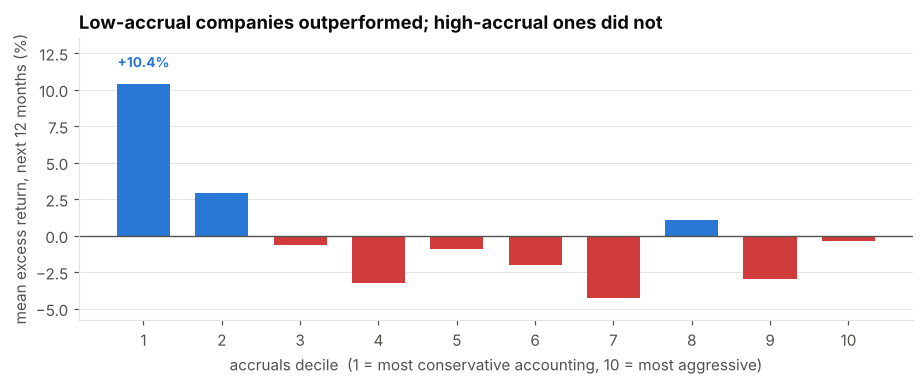

In [13]:
d = b[b["accruals_ratio"].notna()].copy()
d["decile"] = pd.qcut(d["accruals_ratio"], 10, labels=False, duplicates="drop") + 1
by_dec = d.groupby("decile")["excess"].mean()

fig, ax = plt.subplots(figsize=(8.5, 3.6))
colors = [BLUE if v >= 0 else RED for v in by_dec.values]
ax.bar(by_dec.index, by_dec.values * 100, color=colors, width=0.68)
ax.axhline(0, color=MUTED, linewidth=0.9)
ax.set_xticks(range(1, 11))
ax.set_xlabel("accruals decile  (1 = most conservative accounting, 10 = most aggressive)")
ax.set_ylabel("mean excess return, next 12 months (%)")
ax.set_title("Low-accrual companies outperformed; high-accrual ones did not")
ax.grid(axis="x", visible=False)
ax.set_ylim(min(by_dec.values) * 100 * 1.35, max(by_dec.values) * 100 * 1.30)
ax.text(1, by_dec.iloc[0] * 100 + 0.9, f"{by_dec.iloc[0]*100:+.1f}%",
        ha="center", va="bottom", fontsize=9, color=BLUE, fontweight="bold")
plt.tight_layout(); plt.show()

In [14]:
# One good year, or a persistent effect?
d["q"] = d.groupby("entry_year")["accruals_ratio"].transform(
    lambda x: pd.qcut(x, 5, labels=False, duplicates="drop"))
yearly = d.pivot_table(index="entry_year", columns="q", values="forward_return", aggfunc="mean")
yearly = yearly.dropna(subset=[0, yearly.columns.max()])
yearly["spread"] = yearly[yearly.columns.max()] - yearly[0]
wins = int((yearly["spread"] < 0).sum())
print(f"High-accrual quintile underperformed the low-accrual quintile in "
      f"{wins} of {len(yearly)} years.\n")
print("Not one lucky year — a persistent effect.")

High-accrual quintile underperformed the low-accrual quintile in 14 of 17 years.

Not one lucky year — a persistent effect.


### The M-Score does not — and the reason is the interesting part

The raw comparison looked **backwards**: flagged companies *outperformed* by 9.4
percentage points. A model that identifies likely manipulators, whose picks then beat
the market, is not measuring what it claims.

The cause is inside the formula. Beneish's sales growth index carries a **positive**
coefficient — growth creates pressure to sustain it, which was a genuine signal in his
1980s–90s sample. But over 2007–2026 growth was richly rewarded, so the M-Score was
partly a growth factor wearing a fraud costume.

In [15]:
flagged = b[b["m_score_flag"] == True]
others  = b[b["m_score_flag"] != True]
print("Flagged companies are simply growing faster:\n")
print(f"{'':22}{'flagged':>10}{'others':>10}")
for col, label in [("sgi", "sales growth index"), ("revenue_growth", "revenue growth"),
                   ("asset_growth", "asset growth")]:
    print(f"{label:<22}{flagged[col].median():10.2f}{others[col].median():10.2f}")

Flagged companies are simply growing faster:

                         flagged    others
sales growth index          1.27      1.06
revenue growth              0.27      0.06
asset growth                0.49      0.06


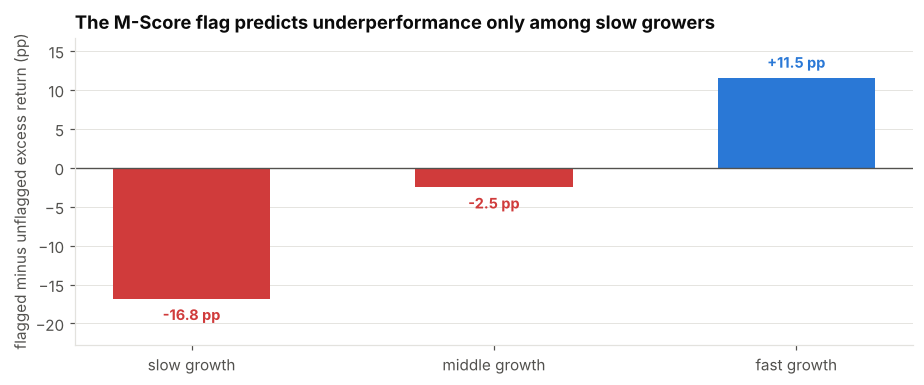

  slow    growth  n=14   flagged   difference  -16.8 pp
  middle  growth  n=17   flagged   difference   -2.5 pp
  fast    growth  n=89   flagged   difference  +11.5 pp

The flag inverts as growth rises: among slow growers it marks companies that
went on to underperform; among fast growers it marks winners.


In [16]:
# Hold growth roughly fixed and the sign flips.
b["growth_band"] = pd.qcut(b["sgi"], 3, labels=["slow", "middle", "fast"])
summary = (b.groupby(["growth_band", b["m_score_flag"] == True], observed=True)["excess"]
             .agg(["mean", "count"]).unstack())

bands = ["slow", "middle", "fast"]
# Unflagged companies sit at roughly zero by construction (excess is measured against
# the peer mean), so plotting them adds no information. The gap is the finding.
diffs = [(summary.loc[g, ("mean", True)] - summary.loc[g, ("mean", False)]) * 100
         for g in bands]
counts = [int(summary.loc[g, ("count", True)]) for g in bands]

fig, ax = plt.subplots(figsize=(8.5, 3.6))
x = np.arange(len(bands))
ax.bar(x, diffs, 0.52, color=[BLUE if d >= 0 else RED for d in diffs])
ax.axhline(0, color=MUTED, linewidth=0.9)
ax.set_xticks(x)
ax.set_xticklabels([f"{b} growth" for b in bands])
ax.set_ylabel("flagged minus unflagged excess return (pp)")
ax.set_title("The M-Score flag predicts underperformance only among slow growers")
ax.grid(axis="x", visible=False)
ax.set_ylim(min(diffs) * 1.35, max(diffs) * 1.45)
for xi, d in zip(x, diffs):
    ax.text(xi, d + (0.9 if d >= 0 else -0.9), f"{d:+.1f} pp", ha="center",
            va="bottom" if d >= 0 else "top", fontsize=9.5, fontweight="bold",
            color=BLUE if d >= 0 else RED)
plt.tight_layout(); plt.show()

for b, c, d in zip(bands, counts, diffs):
    print(f"  {b:<7} growth  n={c:<4} flagged   difference {d:+6.1f} pp")
print()
print("The flag inverts as growth rises: among slow growers it marks companies that")
print("went on to underperform; among fast growers it marks winners.")

---
## Conclusions

1. **Sloan's accrual signal replicates on S&P 500 data, 2007–2026.** An 8.5 percentage
   point spread, p = 0.001, surviving sector and year neutralisation, consistent in 14
   of 17 years. Profit that doesn't become cash is a real warning.

2. **The Beneish M-Score does not survive this test.** Its sales growth term makes it
   partly a growth proxy, and growth outperformed over this period. Among slow-growth
   companies — where the confound is held roughly fixed — flagged names underperformed
   by 18 percentage points (p = 0.027, n = 19: indicative, not conclusive).

3. **Most of what the M-Score flags is M&A, not fraud.** Company-years combining a 25%
   asset jump with receivables outpacing sales were flagged 21× more often than the base
   rate. Any practical screen has to separate those out first.

## Limitations, stated plainly

- **Survivorship bias.** The universe is the *current* S&P 500. Companies that collapsed
  and were delisted are absent — exactly the ones a fraud screen should catch. This
  understates any real signal, and it is the most serious limitation here.
- **Large caps only.** Beneish fitted his model on a broad sample. These are the most
  heavily audited companies in the market, where manipulation is rarest.
- **Small n where it matters most.** The slow-growth M-Score result rests on 19
  company-years.
- **One horizon.** A single 12-month holding period, no risk adjustment beyond
  sector-and-year peer groups.
- **Coverage gaps.** Banks and REITs are excluded by construction. Some companies
  re-tagged lines into company-specific extensions that the EDGAR API does not expose.

None of these signals is evidence of wrongdoing. They say a company's numbers are
unusual relative to its own past and its peers, which has innocent explanations far
more often than not.